In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import sys
import importlib
from pathlib import Path

ROOT_DIR = Path.cwd().parent
sys.path.append(str(ROOT_DIR))

import src.visualization
import src.preproessing
import src.evaluation

importlib.reload(src.visualization)
importlib.reload(src.preproessing)
importlib.reload(src.evaluation)

from src.visualization import (
    plot_target_distribution,
    plot_confusion_matrix,
    heatmap_features,
    plot_model_metrics
)
from src.preproessing import procces_features
from src.evaluation import (
    cross_validate_models,
    evaluate_best_model
)

df = pd.read_csv(
    ROOT_DIR / "data/raw/bank-additional-full.csv",
    sep=";"
)

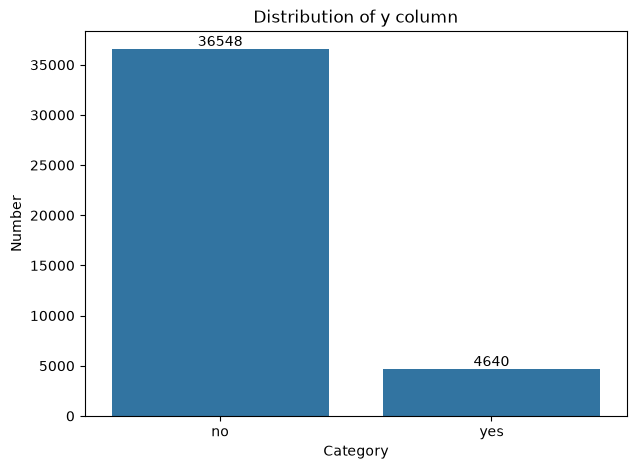

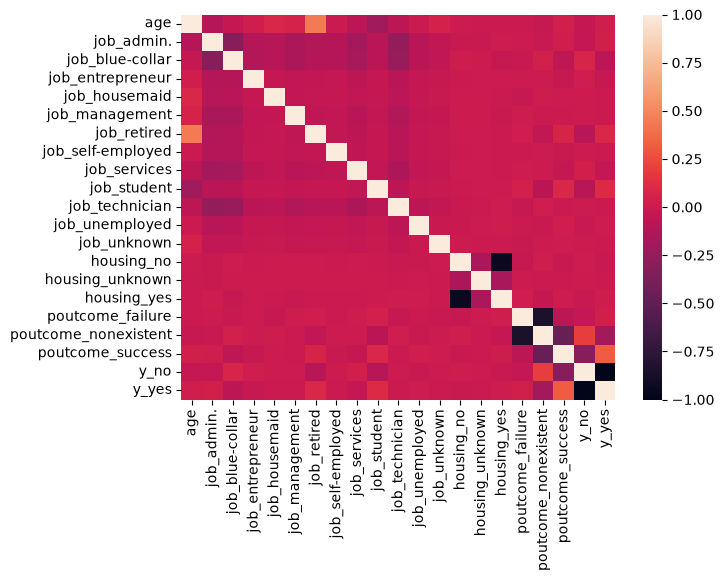

In [3]:
from sklearn.model_selection import train_test_split
df.columns
diff = df[['age','job','housing','poutcome','y']]
X = diff.drop('y',axis=1)
y = diff['y']

plot_target_distribution(df,"y")
heatmap_features(diff)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y,shuffle=True
)

numeric_featrues=['age']
categorical_featrues=['job','housing','poutcome']

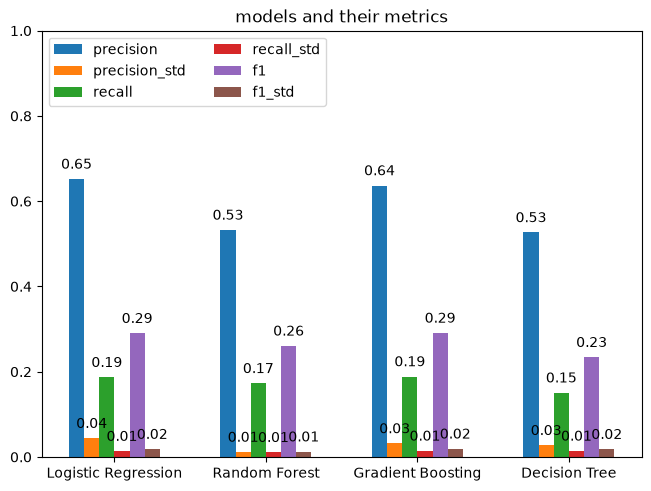

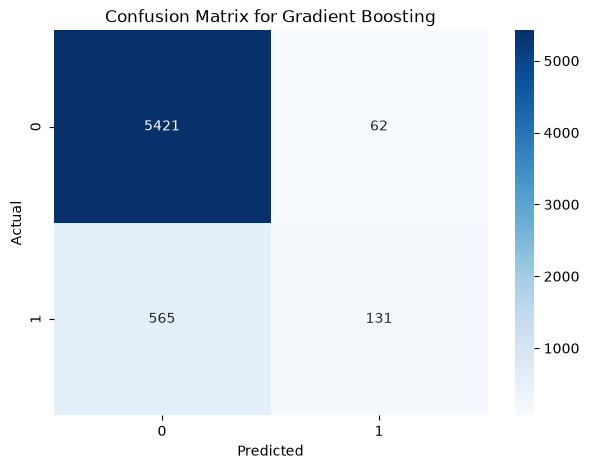

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

preprocessor = procces_features(numeric_featrues,categorical_featrues)
results = cross_validate_models(X_train,y_train,models,preprocessor)
plot_model_metrics(results)
best_model = evaluate_best_model(preprocessor,models[results.T['f1'].idxmax()],X_train,y_train,X_test,y_test)
plot_confusion_matrix(best_model['confusion_matrix'],results.T['f1'].idxmax())